# TAREA 1 · SEMANA 9
# Predicción de notas con regresión lineal

**Reporte de proyecto en Jupyter · 6 horas de referencia**

Estudiante: ____________________  
Curso / docente: ____________________  
Fecha: ____________________

Este cuaderno sustituye el informe e incluye teoría, diagrama de flujo, implementación, resultados ejecutados y conclusiones. Los datos son sintéticos y reproducibles.

## Preparación
Abrir en Jupyter o Google Colab. Ejecutar todas las celdas en orden. Si faltan bibliotecas, instalar requirements.txt o descomentar la siguiente celda.

In [1]:
%matplotlib inline
# %pip install numpy matplotlib scikit-learn scipy tensorflow

## Objetivo y problema
Estimar una nota numérica a partir de horas de estudio y asistencia, comparando modelos con la misma partición de prueba.

## Fundamento: operaciones de la semana 9
El aprendizaje supervisado aprende de entradas X y respuestas conocidas y. Sus dos tareas principales son regresión (cantidades continuas) y clasificación (categorías). Ejemplos de regresión: mínimos cuadrados, árboles y bosques de regresión. Ejemplos de clasificación: regresión logística, k vecinos, árboles y máquinas de vectores de soporte. La regresión logística se usa para clasificación.

La regresión lineal simple usa una entrada: ŷ = β₀ + β₁·horas. La múltiple usa varias: ŷ = β₀ + β₁·horas + β₂·asistencia. Mínimos cuadrados minimiza la suma de errores al cuadrado. Se revisan linealidad, independencia de errores, varianza aproximadamente constante y multicolinealidad. La normalidad del error es relevante para inferencia, no para calcular predicciones.

## Datos y método
240 registros sintéticos: horas entre 0 y 10, asistencia entre 50 y 100 %, nota = 2 + 1.1·horas + 0.06·asistencia + ruido normal. No son estudiantes reales. Se reserva 20 % para prueba antes del entrenamiento. MAE y RMSE expresan error en puntos de nota; R² compara el error con la variabilidad de la respuesta de prueba. Se incluye una base que predice la media del entrenamiento.


## Diagrama de flujo de la función principal
Se dibuja con Python y queda guardado como PNG, sin servicios externos.

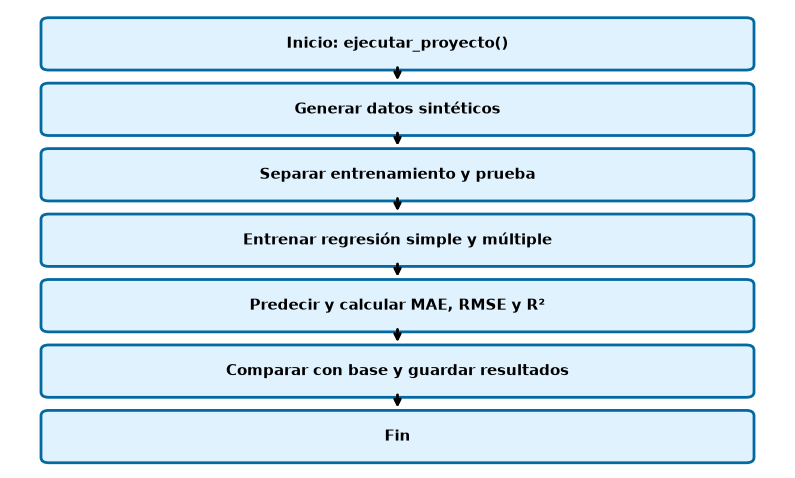

In [2]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
from matplotlib.patches import FancyBboxPatch
pasos=['Inicio: ejecutar_proyecto()', 'Generar datos sintéticos', 'Separar entrenamiento y prueba', 'Entrenar regresión simple y múltiple', 'Predecir y calcular MAE, RMSE y R²', 'Comparar con base y guardar resultados', 'Fin']
fig,ax=plt.subplots(figsize=(10,len(pasos)*.85)); ax.set(xlim=(0,10),ylim=(0,len(pasos)*1.25)); ax.axis('off')
for i,paso in enumerate(pasos):
    y=(len(pasos)-i-1)*1.25+.2
    ax.add_patch(FancyBboxPatch((.5,y),9,.8,boxstyle='round,pad=.1',facecolor='#e0f2fe',edgecolor='#0369a1',linewidth=2))
    ax.text(5,y+.4,paso,ha='center',va='center',fontsize=11,fontweight='bold')
    if i<len(pasos)-1:ax.annotate('',xy=(5,y-.35),xytext=(5,y),arrowprops={'arrowstyle':'->','lw':2})
plt.savefig('resultados/diagrama_flujo.png',dpi=140,bbox_inches='tight'); plt.show()


## Implementación y resultados
Las salidas siguientes proceden de ejecutar este código.

{
  "Base": {
    "MAE": 2.591667070605641,
    "RMSE": 3.0997631707191178,
    "R2": -0.00012796322060792953
  },
  "Simple": {
    "MAE": 1.061801264431946,
    "RMSE": 1.3167485454084897,
    "R2": 0.8195303247776424
  },
  "Multiple": {
    "MAE": 0.6903190508642968,
    "RMSE": 0.8697959436897851,
    "R2": 0.9212531304396545
  }
}
Intercepto y coeficientes múltiples: 1.8866424644945088 [1.12003161 0.05969135]
Predicción: 6 horas y 90 % asistencia: 13.979053801154263


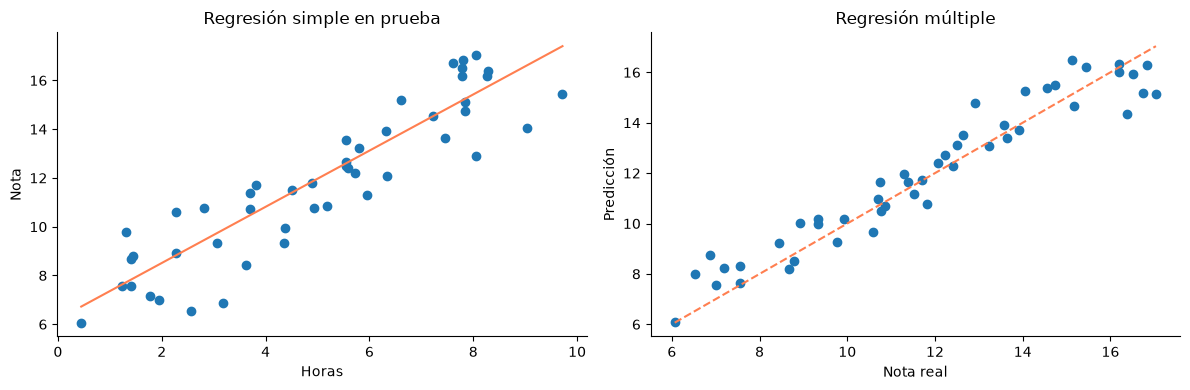

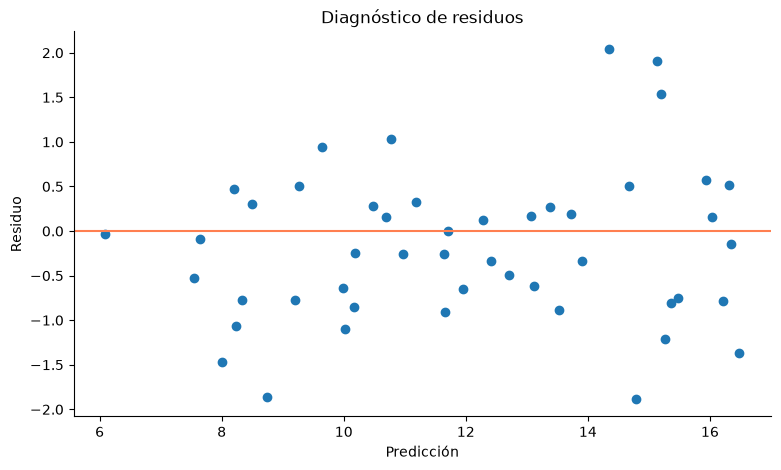

### Interpretación de la ejecución
MAE múltiple: **0.690** puntos; simple: **1.062**; base: **2.592**. La asistencia aporta información porque interviene en la generación de los datos.

338

In [3]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

def ejecutar_proyecto():
    rng=np.random.default_rng(42)
    X=np.column_stack([rng.uniform(0,10,240),rng.uniform(50,100,240)])
    y=2+1.1*X[:,0]+.06*X[:,1]+rng.normal(0,.8,240)
    np.savetxt('datos.csv',np.c_[X,y],delimiter=',',header='horas,asistencia,nota',comments='')
    a,b,c,d=train_test_split(X,y,test_size=.2,random_state=42)
    simple=LinearRegression().fit(a[:,[0]],c)
    multiple=LinearRegression().fit(a,c)
    pred={'Base':np.full_like(d,c.mean()),'Simple':simple.predict(b[:,[0]]),'Multiple':multiple.predict(b)}
    m={k:{'MAE':float(mean_absolute_error(d,v)),'RMSE':float(np.sqrt(mean_squared_error(d,v))),'R2':float(r2_score(d,v))} for k,v in pred.items()}
    print(json.dumps(m,indent=2)); print('Intercepto y coeficientes múltiples:',multiple.intercept_,multiple.coef_)
    print('Predicción: 6 horas y 90 % asistencia:',multiple.predict([[6,90]])[0])
    fig,ax=plt.subplots(1,2,figsize=(12,4))
    ax[0].scatter(b[:,0],d); order=np.argsort(b[:,0]); ax[0].plot(b[order,0],pred['Simple'][order],color='coral')
    ax[0].set(xlabel='Horas',ylabel='Nota',title='Regresión simple en prueba')
    ax[1].scatter(d,pred['Multiple']); ax[1].plot([d.min(),d.max()],[d.min(),d.max()],'--',color='coral')
    ax[1].set(xlabel='Nota real',ylabel='Predicción',title='Regresión múltiple')
    plt.tight_layout(); plt.savefig('resultados/proyecto.png',dpi=140); plt.show()
    plt.scatter(pred['Multiple'],d-pred['Multiple']); plt.axhline(0,color='coral'); plt.xlabel('Predicción'); plt.ylabel('Residuo'); plt.title('Diagnóstico de residuos')
    plt.savefig('resultados/residuos.png',dpi=140); plt.show()
    np.savetxt('resultados/predicciones.csv',np.c_[d,pred['Simple'],pred['Multiple']],delimiter=',',header='real,simple,multiple',comments='')
    display(Markdown(f"### Interpretación de la ejecución\nMAE múltiple: **{m['Multiple']['MAE']:.3f}** puntos; simple: **{m['Simple']['MAE']:.3f}**; base: **{m['Base']['MAE']:.3f}**. La asistencia aporta información porque interviene en la generación de los datos."))
    return m

metricas=ejecutar_proyecto()
Path('resultados/metricas.json').write_text(json.dumps(metricas,indent=2),encoding='utf-8')


## Conclusiones, limitaciones y exploración
La múltiple aprovecha dos entradas y la simple permite visualizar una relación individual. Los residuos permiten explorar fallos de linealidad. Los coeficientes expresan asociación, no causalidad. El experimento sintético no garantiza rendimiento en estudiantes reales. Explorar: aumentar el ruido a 2 y comparar el MAE; retirar asistencia y explicar la pérdida de información.

## Referencias oficiales
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html